# Model 1 — Jewelry Image Generation with Stable Diffusion 1.5 + LoRA

## Corrected and reproducible training notebook

This notebook is a cleaned-up version of the original **Stable Diffusion 1.5 + PEFT LoRA** experiment. It keeps the original jewelry dataset/caption structure but fixes the main training issues identified during review.

### Main corrections
1. **No silent black-image fallback** — missing/corrupt images stop the run before training.
2. **Reproducible train/validation split** when the CSV does not already contain a split.
3. **Aspect-ratio-safe preprocessing** by default: resize the longest side and pad instead of blindly center-cropping jewelry.
4. **Deterministic VAE latent caching** using the VAE latent mean rather than a permanently cached random sample.
5. **Actual Min-SNR-$\gamma$ loss weighting** with $\gamma=5$.
6. **FP16 GradScaler** for CUDA mixed-precision training.
7. **Correct gradient-accumulation step calculation** using `ceil`, including the final partial accumulation.
8. **Real early stopping** in addition to best-checkpoint saving.
9. **Learning-rate schedule no longer reaches zero too early**; the default experiment uses a small LR and constant-with-warmup scheduling.
10. **Validation is deterministic** and uses the same prompts/noise/timesteps every epoch.
11. **Base-vs-LoRA CLIP benchmark** is included instead of claiming an after-only score is a before/after benchmark.
12. **Training statistics and configuration are saved** with the checkpoints.


## 1. Environment

Recommended for Google Colab: **T4 or better**. A GPU is strongly recommended.

If packages are already installed, you can skip the installation cell.


In [1]:
# Uncomment if using a fresh Colab/runtime.
# !pip install -q -U diffusers transformers peft accelerate safetensors torchvision tqdm matplotlib pandas

import os
import json
import math
import random
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from transformers import CLIPTokenizer, CLIPTextModel, CLIPProcessor, CLIPModel
from diffusers import (
    AutoencoderKL,
    UNet2DConditionModel,
    DDPMScheduler,
    StableDiffusionPipeline,
    DPMSolverMultistepScheduler,
)
from diffusers.optimization import get_constant_schedule_with_warmup
from peft import LoraConfig, PeftModel, get_peft_model

print('=' * 72)
print('ENVIRONMENT')
print('=' * 72)
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())

if torch.cuda.is_available():
    device = torch.device('cuda')
    print('GPU:', torch.cuda.get_device_name(0))
    print('VRAM:', f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    device = torch.device('cpu')
    warnings.warn('CUDA is not available. Training Stable Diffusion on CPU will be extremely slow.')

print('Device:', device)


ENVIRONMENT
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 3060 Laptop GPU
VRAM: 6.44 GB
Device: cuda


## 2. Reproducibility and experiment configuration

Change only the configuration values in this section when running controlled experiments.


In [2]:
# -------------------- Experiment configuration --------------------
SEED = 42
MODEL_NAME = 'runwayml/stable-diffusion-v1-5'
IMAGE_SIZE = 512

# Set this to your dataset directory if automatic discovery does not find it.
# Example: DATA_DIR_OVERRIDE = '/content/drive/MyDrive/design_dataset'
DATA_DIR_OVERRIDE = None

# Training
BATCH_SIZE = 4
GRADIENT_ACCUMULATION_STEPS = 2
NUM_EPOCHS = 8
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 1e-4
WARMUP_STEPS = 100
MAX_GRAD_NORM = 1.0

# LoRA
LORA_R = 16
LORA_ALPHA = 16
LORA_DROPOUT = 0.05
LORA_TARGET_MODULES = ['to_k', 'to_q', 'to_v', 'to_out.0']

# Diffusion loss
MIN_SNR_GAMMA = 5.0

# Prompt conditioning
UNCOND_PROBABILITY = 0.10
NARRATIVE_PROBABILITY = 0.65

# Augmentation / preprocessing
RANDOM_HORIZONTAL_FLIP = True
USE_CENTER_CROP = False  # False is safer for long/asymmetric jewelry.

# Early stopping
EARLY_STOP_PATIENCE = 4
MIN_VAL_IMPROVEMENT = 1e-4

# Mixed precision
USE_FP16 = torch.cuda.is_available()

# Cache version prevents accidental reuse of incompatible old latent caches.
CACHE_VERSION = 'v2_mean_latents_512_aspect_safe'

def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

print(json.dumps({
    'seed': SEED,
    'model': MODEL_NAME,
    'image_size': IMAGE_SIZE,
    'batch_size': BATCH_SIZE,
    'gradient_accumulation': GRADIENT_ACCUMULATION_STEPS,
    'epochs': NUM_EPOCHS,
    'learning_rate': LEARNING_RATE,
    'min_snr_gamma': MIN_SNR_GAMMA,
    'fp16': USE_FP16,
}, indent=2))


{
  "seed": 42,
  "model": "runwayml/stable-diffusion-v1-5",
  "image_size": 512,
  "batch_size": 4,
  "gradient_accumulation": 2,
  "epochs": 8,
  "learning_rate": 2e-05,
  "min_snr_gamma": 5.0,
  "fp16": true
}


## 3. Locate and load the jewelry dataset

The original notebook supports `enhanced_metadata.csv` and `metadata.csv`, and expects an `image_path` column when available.

**Important correction:** if an image cannot be found, the notebook now raises an error instead of silently substituting a black image.


In [3]:
POSSIBLE_DATA_DIRS = [
    os.path.join(os.getcwd(), '..', 'data', 'design_dataset'),
    os.path.join(os.getcwd(), 'data', 'design_dataset'),
    os.path.join(os.getcwd(), 'design_dataset'),
]

if DATA_DIR_OVERRIDE:
    POSSIBLE_DATA_DIRS.insert(0, DATA_DIR_OVERRIDE)

base_data_dir = None
for p in POSSIBLE_DATA_DIRS:
    p = os.path.abspath(p)
    if os.path.isdir(p) and (
        os.path.exists(os.path.join(p, 'enhanced_metadata.csv'))
        or os.path.exists(os.path.join(p, 'metadata.csv'))
    ):
        base_data_dir = p
        break

if base_data_dir is None:
    raise FileNotFoundError(
        'Could not locate the jewelry dataset. Set DATA_DIR_OVERRIDE to the folder containing enhanced_metadata.csv or metadata.csv.'
    )

csv_path = os.path.join(base_data_dir, 'enhanced_metadata.csv')
if not os.path.exists(csv_path):
    csv_path = os.path.join(base_data_dir, 'metadata.csv')

df = pd.read_csv(csv_path)
print('Dataset:', base_data_dir)
print('CSV:', csv_path)
print('Records:', len(df))
print('Columns:', list(df.columns))

# Normalize caption source. Keep the original dataset terminology where possible.
if 'caption_narrative' in df.columns:
    df['training_caption'] = df['caption_narrative'].fillna('').astype(str)
elif 'caption' in df.columns:
    df['training_caption'] = df['caption'].fillna('').astype(str)
else:
    required = ['gemstone_color', 'category', 'metal']
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise KeyError(f'No caption column found and required fallback columns are missing: {missing}')
    df['training_caption'] = (
        df['gemstone_color'].fillna('').astype(str) + ' ' +
        df['category'].fillna('').astype(str) + ' in ' +
        df['metal'].fillna('').astype(str)
    )

# Create a reproducible split only when the dataset does not already provide one.
if 'split' not in df.columns:
    rng = np.random.default_rng(SEED)
    mask = rng.random(len(df)) < 0.85
    # Guarantee that neither side is empty for small datasets.
    if mask.all():
        mask[rng.integers(0, len(mask))] = False
    if (~mask).all():
        mask[rng.integers(0, len(mask))] = True
    df['split'] = np.where(mask, 'train', 'validation')
else:
    df['split'] = df['split'].astype(str).str.lower().replace({'val': 'validation', 'valid': 'validation'})

train_df = df[df['split'] == 'train'].reset_index(drop=True)
val_df = df[df['split'] != 'train'].reset_index(drop=True)

if len(train_df) == 0 or len(val_df) == 0:
    raise ValueError(f'Invalid split: train={len(train_df)}, validation={len(val_df)}')

print(f'Train: {len(train_df)}')
print(f'Validation: {len(val_df)}')
print('\nSample captions:')
display(train_df[[c for c in ['image_id', 'category', 'metal', 'training_caption'] if c in train_df.columns]].head(5))


Dataset: e:\GIT\Jewelery Models Development\data\design_dataset
CSV: e:\GIT\Jewelery Models Development\data\design_dataset\enhanced_metadata.csv
Records: 1503
Columns: ['image_id', 'image_path', 'split', 'category', 'gemstone', 'gemstone_color', 'gemstone_cut', 'weight_carats', 'metal', 'setting', 'style', 'occasion', 'caption_tags', 'caption_narrative', 'source_file']
Train: 1303
Validation: 200

Sample captions:


,image_id,category,metal,training_caption
0,J0001,earring,sterling silver,A pair of round stud earrings featuring deep b...
1,J0002,earring,yellow gold,A pair of elegant stud earrings featuring a pr...
2,J0003,earring,white gold,A pair of elaborate fan-shaped earrings featur...
3,J0004,earring,white gold,A pair of delicate flower-shaped stud earrings...
4,J0005,earring,white gold,A pair of square-shaped stud earrings featurin...


## 4. Dataset path validation — run this before loading the model

This is intentionally strict. A missing image should be fixed in the dataset rather than converted into a black training example.


In [4]:
class ImagePathResolver:
    def __init__(self, base_dir):
        self.base_dir = base_dir
        self.img_dirs = [
            os.path.join(base_dir, 'images'),
            base_dir,
            os.path.join(base_dir, 'images', 'train'),
            os.path.join(base_dir, 'images', 'validation'),
        ]

    def find(self, raw_path):
        raw_path = str(raw_path)
        if os.path.isabs(raw_path) and os.path.isfile(raw_path):
            return raw_path
        normalized = raw_path.replace('/', os.sep).replace('\\', os.sep)
        for d in self.img_dirs:
            candidate = os.path.join(d, normalized)
            if os.path.isfile(candidate):
                return candidate
            candidate = os.path.join(d, os.path.basename(normalized))
            if os.path.isfile(candidate):
                return candidate
        return None

resolver = ImagePathResolver(base_data_dir)

def row_image_reference(row):
    if 'image_path' in row.index and pd.notna(row['image_path']) and str(row['image_path']).strip():
        return str(row['image_path'])
    if 'image_id' not in row.index:
        raise KeyError('Dataset needs image_path or image_id.')
    return f"{row['image_id']}.jpg"

missing_rows = []
corrupt_rows = []
resolved_paths = {}

for split_name, split_df in [('train', train_df), ('validation', val_df)]:
    for idx, row in split_df.iterrows():
        raw = row_image_reference(row)
        path = resolver.find(raw)
        key = f'{split_name}:{idx}'
        if path is None:
            missing_rows.append((split_name, idx, raw))
            continue
        try:
            with Image.open(path) as im:
                im.verify()
            resolved_paths[key] = path
        except Exception as exc:
            corrupt_rows.append((split_name, idx, raw, str(exc)))

print(f'Resolved images : {len(resolved_paths)}')
print(f'Missing images  : {len(missing_rows)}')
print(f'Corrupt images  : {len(corrupt_rows)}')

if missing_rows:
    print('First missing files:')
    for item in missing_rows[:20]:
        print(' ', item)
if corrupt_rows:
    print('First corrupt files:')
    for item in corrupt_rows[:20]:
        print(' ', item)

if missing_rows or corrupt_rows:
    raise FileNotFoundError(
        'Dataset validation failed. Fix the missing/corrupt image paths above and rerun this cell before training.'
    )

print('\nDataset validation PASSED.')


Resolved images : 1503
Missing images  : 0
Corrupt images  : 0

Dataset validation PASSED.


## 5. Visual dataset inspection

This section helps catch incorrect crops, extreme aspect ratios, empty images, or unexpected metadata before expensive VAE encoding.


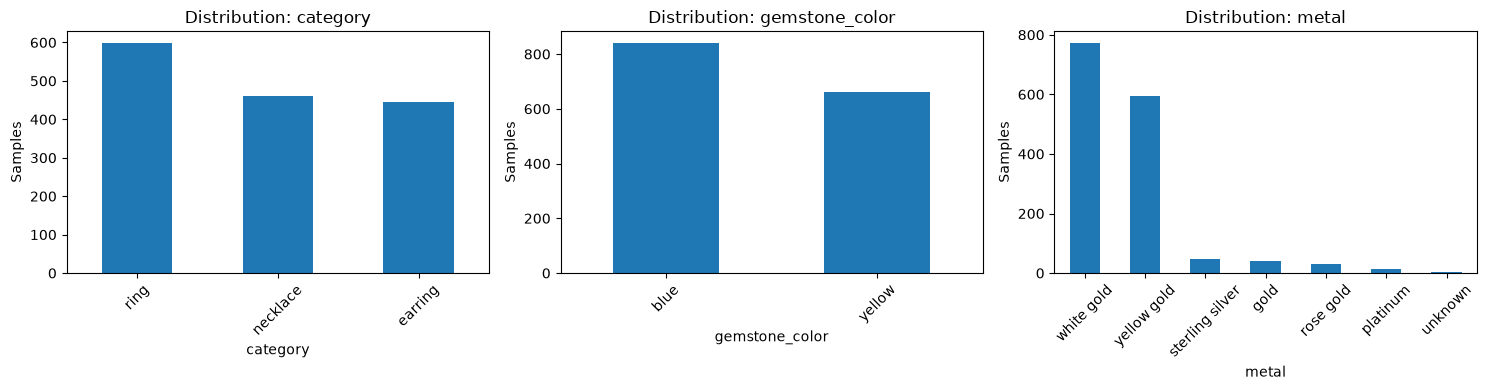

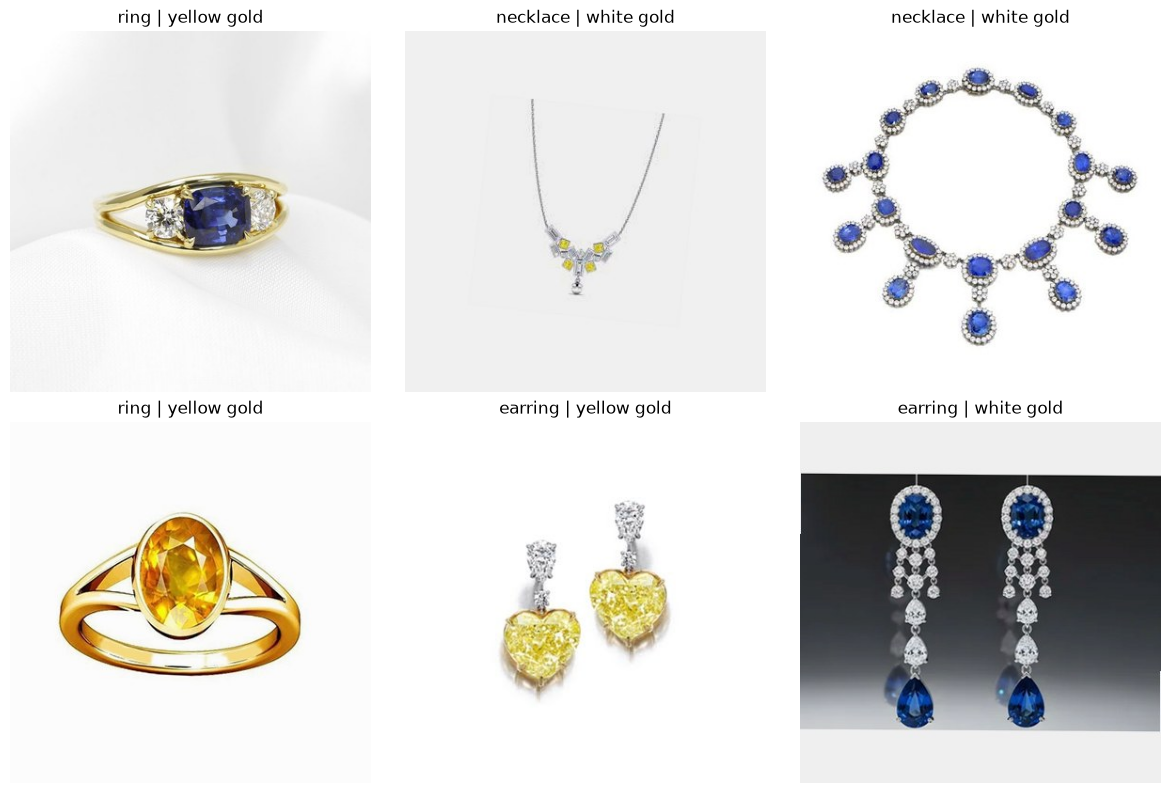

In [5]:
# Basic distributions if these columns exist.
plot_columns = [c for c in ['category', 'gemstone_color', 'metal'] if c in df.columns]
if plot_columns:
    fig, axes = plt.subplots(1, len(plot_columns), figsize=(5 * len(plot_columns), 4))
    if len(plot_columns) == 1:
        axes = [axes]
    for ax, col in zip(axes, plot_columns):
        df[col].fillna('unknown').astype(str).value_counts().head(15).plot(kind='bar', ax=ax)
        ax.set_title(f'Distribution: {col}')
        ax.set_ylabel('Samples')
        ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()

# Image gallery
sample_rows = train_df.sample(min(6, len(train_df)), random_state=SEED).reset_index(drop=True)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.ravel()
for ax in axes:
    ax.axis('off')

for i, (_, row) in enumerate(sample_rows.iterrows()):
    path = resolver.find(row_image_reference(row))
    image = Image.open(path).convert('RGB')
    axes[i].imshow(image)
    title = f"{row.get('category', 'jewelry')} | {row.get('metal', '')}"
    axes[i].set_title(title[:70])
    axes[i].axis('off')

plt.tight_layout()
plt.show()


## 6. Load Stable Diffusion 1.5

VAE and CLIP text encoder remain frozen. The UNet will receive LoRA adapters.


In [6]:
print('Loading Stable Diffusion 1.5 components...')

tokenizer = CLIPTokenizer.from_pretrained(MODEL_NAME, subfolder='tokenizer')
text_encoder = CLIPTextModel.from_pretrained(MODEL_NAME, subfolder='text_encoder')
vae = AutoencoderKL.from_pretrained(MODEL_NAME, subfolder='vae')
unet = UNet2DConditionModel.from_pretrained(MODEL_NAME, subfolder='unet')
noise_scheduler = DDPMScheduler.from_pretrained(MODEL_NAME, subfolder='scheduler')

vae.requires_grad_(False).eval().to(device)
text_encoder.requires_grad_(False).eval().to(device)
unet.enable_gradient_checkpointing()

if USE_FP16 and torch.cuda.is_available():
    vae.to(dtype=torch.float16)
    text_encoder.to(dtype=torch.float16)

print('Loaded.')
print('VAE dtype:', next(vae.parameters()).dtype)
print('Text encoder dtype:', next(text_encoder.parameters()).dtype)
print('UNet dtype:', next(unet.parameters()).dtype)
print('Scheduler timesteps:', noise_scheduler.config.num_train_timesteps)


Could not reach the Hub ([Errno 11001] getaddrinfo failed). Using cached commit hash for 'runwayml/stable-diffusion-v1-5'.
Could not reach the Hub ([Errno 11001] getaddrinfo failed). Using cached commit hash for 'runwayml/stable-diffusion-v1-5'.


Loading Stable Diffusion 1.5 components...


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

e:\GIT\Jewelery Models Development\.venv\Lib\site-packages\huggingface_hub\utils\_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/runwayml/stable-diffusion-v1-5/resolve/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/vae/diffusion_pytorch_model.safetensors.index.json
Retrying in 1s [Retry 1/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/runwayml/stable-diffusion-v1-5/resolve/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/vae/diffusion_pytorch_model.safetensors.index.json
Retrying in 2s [Retry 2/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/runwayml/stable-diffusion-v1-5/resolve/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/vae/diffusion_pytorch_model.safetensors.index.json
Retrying 

Loaded.
VAE dtype: torch.float16
Text encoder dtype: torch.float16
UNet dtype: torch.float32
Scheduler timesteps: 1000


## 7. Dataset preprocessing and prompt construction

### Important preprocessing change

The original notebook used `Resize(512) + CenterCrop(512)`. For jewelry, this can cut off long necklaces, earrings, or off-center products. The default below instead scales the **longest side to 512** and pads to a square.

Set `USE_CENTER_CROP = True` if your dataset is already square and you have verified that cropping is harmless.


In [7]:
class ResizePadSquare:
    """Resize the longest side to image_size and pad the remaining area."""
    def __init__(self, image_size=512, fill=(0, 0, 0)):
        self.image_size = image_size
        self.fill = fill

    def __call__(self, image):
        image = image.convert('RGB')
        w, h = image.size
        scale = self.image_size / max(w, h)
        nw = max(1, round(w * scale))
        nh = max(1, round(h * scale))
        image = image.resize((nw, nh), Image.Resampling.BICUBIC)
        canvas = Image.new('RGB', (self.image_size, self.image_size), self.fill)
        left = (self.image_size - nw) // 2
        top = (self.image_size - nh) // 2
        canvas.paste(image, (left, top))
        return canvas

class JewelryDiffusionDataset(Dataset):
    def __init__(self, df, base_dir, image_size=512, is_train=True, uncond_p=0.10):
        self.df = df.reset_index(drop=True)
        self.base_dir = base_dir
        self.is_train = is_train
        self.uncond_p = uncond_p
        self.resolver = ImagePathResolver(base_dir)

        if USE_CENTER_CROP:
            image_transform = transforms.Compose([
                transforms.Resize(image_size, interpolation=transforms.InterpolationMode.BICUBIC),
                transforms.CenterCrop(image_size),
            ])
        else:
            image_transform = ResizePadSquare(image_size)

        self.transform = transforms.Compose([
            image_transform,
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ])

    def _build_caption(self, row):
        if not self.is_train:
            narrative = str(row.get('caption_narrative', '')).strip()
            return narrative if narrative else str(row.get('training_caption', '')).strip()

        if random.random() < self.uncond_p:
            return ''

        narrative = str(row.get('caption_narrative', '')).strip()
        if narrative and random.random() < NARRATIVE_PROBABILITY:
            return narrative

        category = str(row.get('category', 'jewelry')).strip()
        metal = str(row.get('metal', '18K gold')).strip()
        color = str(row.get('gemstone_color', 'blue')).strip()
        gem = str(row.get('gemstone', 'sapphire')).strip()
        cut = str(row.get('gemstone_cut', 'oval cut')).strip()
        setting = str(row.get('setting', 'prong setting')).strip()
        style = str(row.get('style', 'classic')).strip()

        return (
            f'A bespoke {metal} {category} featuring a {color} {gem}, '
            f'{cut}, {setting}, {style} style, studio jewelry product photography'
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        raw_path = row_image_reference(row)
        full_path = self.resolver.find(raw_path)

        # Strict failure: never train on a synthetic black placeholder.
        if full_path is None:
            raise FileNotFoundError(f'Image not found for dataset index {idx}: {raw_path}')

        try:
            with Image.open(full_path) as im:
                image = im.convert('RGB')
        except Exception as exc:
            raise RuntimeError(f'Could not open image {full_path}: {exc}') from exc

        return {
            'pixel_values': self.transform(image),
            'caption': self._build_caption(row),
        }

train_dataset = JewelryDiffusionDataset(train_df, base_data_dir, IMAGE_SIZE, True, UNCOND_PROBABILITY)
val_dataset = JewelryDiffusionDataset(val_df, base_data_dir, IMAGE_SIZE, False, 0.0)

print('Train items:', len(train_dataset))
print('Validation items:', len(val_dataset))
print('Example training caption:', repr(train_dataset[0]['caption']))


Train items: 1303
Validation items: 200
Example training caption: 'A pair of round stud earrings featuring deep blue, faceted gemstones securely held in a prong setting of polished silver-toned metal, featuring a 2.25 carat stone, crisp macro jewelry photography with clean studio lighting.'


## 8. Deterministic VAE latent caching

The original notebook permanently cached a random sample from the VAE latent distribution. This version caches the **latent mean**, which makes the cache reproducible and prevents a new random VAE sample from being accidentally frozen into every experiment.

The cache filename includes a version string so it does not accidentally reuse incompatible old latents.


In [8]:
project_root = os.path.abspath(os.path.join(os.getcwd(), '..')) if 'notebooks' in os.getcwd() else os.getcwd()
artifact_dir = os.path.join(project_root, 'artifacts')
cache_dir = os.path.join(artifact_dir, 'cached_latents')
checkpoint_dir = os.path.join(artifact_dir, 'model1_checkpoints_fixed')
os.makedirs(cache_dir, exist_ok=True)
os.makedirs(checkpoint_dir, exist_ok=True)

train_latents_path = os.path.join(cache_dir, f'train_latents_{CACHE_VERSION}.pt')
val_latents_path = os.path.join(cache_dir, f'val_latents_{CACHE_VERSION}.pt')

@torch.no_grad()
def get_or_create_latents(raw_dataset, vae_model, save_path, batch_size=8):
    if os.path.exists(save_path):
        print('Loading cached latents:', save_path)
        data = torch.load(save_path, map_location='cpu')
        if data.ndim != 4 or data.shape[1:] != (4, IMAGE_SIZE // 8, IMAGE_SIZE // 8):
            raise ValueError(f'Latent cache has unexpected shape: {tuple(data.shape)}')
        if data.shape[0] != len(raw_dataset):
            raise ValueError('Latent cache length does not match current dataset split. Delete the cache and rerun.')
        return data

    loader = DataLoader(
        raw_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        collate_fn=lambda batch: torch.stack([x['pixel_values'] for x in batch]),
    )

    vae_dtype = next(vae_model.parameters()).dtype
    cached = []
    split_name = 'train' if raw_dataset.is_train else 'validation'

    print(f'Encoding {split_name} images with VAE...')
    for pixel_batch in tqdm(loader, desc=f'VAE encode [{split_name}]'):
        pixel_batch = pixel_batch.to(device=device, dtype=vae_dtype)
        latent_dist = vae_model.encode(pixel_batch).latent_dist
        latents = latent_dist.mean * vae_model.config.scaling_factor
        cached.append(latents.cpu().to(torch.float16))

    all_latents = torch.cat(cached, dim=0)
    torch.save(all_latents, save_path)
    print('Saved:', save_path, '| shape:', tuple(all_latents.shape))
    return all_latents

train_latents = get_or_create_latents(train_dataset, vae, train_latents_path)
val_latents = get_or_create_latents(val_dataset, vae, val_latents_path)

print('Train latent shape:', tuple(train_latents.shape))
print('Validation latent shape:', tuple(val_latents.shape))


Loading cached latents: e:\GIT\Jewelery Models Development\artifacts\cached_latents\train_latents_v2_mean_latents_512_aspect_safe.pt
Loading cached latents: e:\GIT\Jewelery Models Development\artifacts\cached_latents\val_latents_v2_mean_latents_512_aspect_safe.pt
Train latent shape: (1303, 4, 64, 64)
Validation latent shape: (200, 4, 64, 64)


In [9]:
class CachedJewelryDataset(Dataset):
    def __init__(self, raw_dataset, cached_latents, is_train):
        self.raw_dataset = raw_dataset
        self.cached_latents = cached_latents
        self.is_train = is_train

    def __len__(self):
        return len(self.raw_dataset)

    def __getitem__(self, idx):
        latent = self.cached_latents[idx].clone().float()

        if self.is_train and RANDOM_HORIZONTAL_FLIP and random.random() < 0.5:
            latent = torch.flip(latent, dims=[-1])

        row = self.raw_dataset.df.iloc[idx]
        return {
            'latent': latent,
            'caption': self.raw_dataset._build_caption(row),
        }


cached_train_dataset = CachedJewelryDataset(train_dataset, train_latents, True)
cached_val_dataset = CachedJewelryDataset(val_dataset, val_latents, False)

def collate_fn(batch):
    latents = torch.stack([x['latent'] for x in batch])
    captions = [x['caption'] for x in batch]
    tokenized = tokenizer(
        captions,
        max_length=tokenizer.model_max_length,
        padding='max_length',
        truncation=True,
        return_tensors='pt',
    )
    return {'latents': latents, 'input_ids': tokenized.input_ids}

train_loader = DataLoader(
    cached_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    collate_fn=collate_fn,
    pin_memory=torch.cuda.is_available(),
)
val_loader = DataLoader(
    cached_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn,
    pin_memory=torch.cuda.is_available(),
)

optimizer_steps_per_epoch = math.ceil(len(train_loader) / GRADIENT_ACCUMULATION_STEPS)
total_training_steps = optimizer_steps_per_epoch * NUM_EPOCHS

print('Train batches / epoch:', len(train_loader))
print('Validation batches / epoch:', len(val_loader))
print('Optimizer steps / epoch:', optimizer_steps_per_epoch)
print('Total optimizer steps:', total_training_steps)


Train batches / epoch: 326
Validation batches / epoch: 50
Optimizer steps / epoch: 163
Total optimizer steps: 1304


## 9. Inject LoRA into the UNet

Only the LoRA parameters are trainable. The base UNet weights remain frozen.


In [10]:
# Make sure the base UNet is clean if this cell is accidentally rerun.
if isinstance(unet, PeftModel):
    unet = unet.unload()

lora_config = LoraConfig(
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    target_modules=LORA_TARGET_MODULES,
    lora_dropout=LORA_DROPOUT,
    bias='none',
)

unet = get_peft_model(unet, lora_config)
unet.to(device)

trainable_params = [p for p in unet.parameters() if p.requires_grad]
trainable_count = sum(p.numel() for p in trainable_params)
total_count = sum(p.numel() for p in unet.parameters())

print(f'Trainable LoRA parameters: {trainable_count:,}')
print(f'Total UNet parameters:     {total_count:,}')
print(f'Trainable percentage:       {100 * trainable_count / total_count:.3f}%')

if trainable_count == 0:
    raise RuntimeError('No trainable LoRA parameters were found.')


Trainable LoRA parameters: 3,188,736
Total UNet parameters:     862,709,700
Trainable percentage:       0.370%


## 10. Correct diffusion loss — Min-SNR-$\gamma$ = 5

The original notebook claimed Min-SNR weighting but actually used plain MSE. This implementation performs the timestep-dependent weighting explicitly.


In [11]:
def compute_diffusion_loss(noise_pred, target_noise, timesteps, scheduler, gamma=5.0):
    """
    Epsilon-prediction MSE with Min-SNR weighting.

    Returns one weighted scalar loss.
    """
    per_example_mse = F.mse_loss(
        noise_pred.float(),
        target_noise.float(),
        reduction='none',
    ).mean(dim=(1, 2, 3))

    alphas_cumprod = scheduler.alphas_cumprod.to(
        device=noise_pred.device,
        dtype=torch.float32,
    )
    alpha_t = alphas_cumprod[timesteps]
    snr = alpha_t / torch.clamp(1.0 - alpha_t, min=1e-8)

    weights = torch.minimum(
        snr,
        torch.full_like(snr, gamma),
    ) / torch.clamp(snr, min=1e-8)

    return (per_example_mse * weights).mean()

print('Min-SNR gamma:', MIN_SNR_GAMMA)


Min-SNR gamma: 5.0


## 11. Training — FP16 GradScaler, warmup, best checkpoint, and real early stopping

### Why this version is different
- Uses **AdamW** with `2e-5` learning rate.
- Uses **100 warmup steps** followed by a constant LR rather than decaying to zero during a short 5-epoch run.
- Uses **GradScaler** for FP16 CUDA training.
- Uses **gradient clipping** before every optimizer step.
- Uses deterministic validation noise/timesteps every epoch.
- Saves the best adapter.
- Stops when validation loss fails to improve for `EARLY_STOP_PATIENCE` epochs.


In [12]:
best_checkpoint_path = os.path.join(checkpoint_dir, 'best_jewelry_lora_adapter')
final_checkpoint_path = os.path.join(checkpoint_dir, 'final_jewelry_lora_adapter')
config_path = os.path.join(checkpoint_dir, 'training_config.json')
metrics_path = os.path.join(checkpoint_dir, 'training_metrics.json')

training_config = {
    'seed': SEED,
    'model_name': MODEL_NAME,
    'image_size': IMAGE_SIZE,
    'batch_size': BATCH_SIZE,
    'gradient_accumulation_steps': GRADIENT_ACCUMULATION_STEPS,
    'epochs_max': NUM_EPOCHS,
    'learning_rate': LEARNING_RATE,
    'weight_decay': WEIGHT_DECAY,
    'warmup_steps': WARMUP_STEPS,
    'min_snr_gamma': MIN_SNR_GAMMA,
    'lora_r': LORA_R,
    'lora_alpha': LORA_ALPHA,
    'lora_dropout': LORA_DROPOUT,
    'lora_target_modules': LORA_TARGET_MODULES,
    'uncond_probability': UNCOND_PROBABILITY,
    'narrative_probability': NARRATIVE_PROBABILITY,
    'random_horizontal_flip': RANDOM_HORIZONTAL_FLIP,
    'use_center_crop': USE_CENTER_CROP,
    'early_stop_patience': EARLY_STOP_PATIENCE,
    'min_val_improvement': MIN_VAL_IMPROVEMENT,
}
with open(config_path, 'w', encoding='utf-8') as f:
    json.dump(training_config, f, indent=2)

optimizer = torch.optim.AdamW(
    trainable_params,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)
lr_scheduler = get_constant_schedule_with_warmup(
    optimizer,
    num_warmup_steps=min(WARMUP_STEPS, total_training_steps),
)

scaler = torch.cuda.amp.GradScaler(enabled=USE_FP16)

train_losses = []
val_losses = []
lr_history = []
best_val_loss = float('inf')
best_epoch = 0
patience_counter = 0

# Precompute deterministic validation noise/timesteps once so every epoch evaluates exactly the same problem.
val_rng = torch.Generator(device=device).manual_seed(SEED) if device.type == 'cuda' else torch.Generator().manual_seed(SEED)
val_fixed_batches = []
for val_batch in val_loader:
    latents = val_batch['latents']
    timesteps = torch.randint(
        0, noise_scheduler.config.num_train_timesteps,
        (latents.shape[0],),
        generator=val_rng,
        device=device,
    ).long()
    noise = torch.randn(
        latents.shape,
        generator=val_rng,
        device=device,
    )
    val_fixed_batches.append({
        'latents': latents,
        'input_ids': val_batch['input_ids'],
        'timesteps': timesteps,
        'noise': noise,
    })

print('=' * 72)
print('STARTING LoRA TRAINING')
print('Max epochs:', NUM_EPOCHS)
print('Optimizer steps:', total_training_steps)
print('Early stopping patience:', EARLY_STOP_PATIENCE)
print('=' * 72)

for epoch in range(1, NUM_EPOCHS + 1):
    seed_everything(SEED + epoch)
    unet.train()

    running_train_loss = 0.0
    optimizer.zero_grad(set_to_none=True)

    progress = tqdm(train_loader, desc=f'Epoch {epoch:02d}/{NUM_EPOCHS} [Train]')
    for step, batch in enumerate(progress):
        latents = batch['latents'].to(device, non_blocking=True)
        input_ids = batch['input_ids'].to(device, non_blocking=True)

        with torch.no_grad():
            encoder_hidden_states = text_encoder(input_ids)[0]

        noise = torch.randn_like(latents)
        timesteps = torch.randint(
            0, noise_scheduler.config.num_train_timesteps,
            (latents.shape[0],),
            device=device,
        ).long()
        noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

        autocast_enabled = USE_FP16 and device.type == 'cuda'
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=autocast_enabled):
            noise_pred = unet(
                noisy_latents,
                timesteps,
                encoder_hidden_states,
            ).sample
            loss = compute_diffusion_loss(
                noise_pred, noise, timesteps, noise_scheduler, MIN_SNR_GAMMA
            )
            scaled_loss = loss / GRADIENT_ACCUMULATION_STEPS

        scaler.scale(scaled_loss).backward()

        should_step = (
            (step + 1) % GRADIENT_ACCUMULATION_STEPS == 0
            or (step + 1) == len(train_loader)
        )

        if should_step:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable_params, MAX_GRAD_NORM)
            scaler.step(optimizer)
            scaler.update()
            lr_scheduler.step()
            optimizer.zero_grad(set_to_none=True)

        running_train_loss += loss.item()
        progress.set_postfix({
            'loss': f'{loss.item():.4f}',
            'lr': f'{lr_scheduler.get_last_lr()[0]:.2e}',
        })

    avg_train_loss = running_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    lr_history.append(lr_scheduler.get_last_lr()[0])

    # ---------------- Validation ----------------
    unet.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for batch in tqdm(val_fixed_batches, desc=f'Epoch {epoch:02d}/{NUM_EPOCHS} [Val]', leave=False):
            latents = batch['latents'].to(device)
            input_ids = batch['input_ids'].to(device)
            timesteps = batch['timesteps']
            noise = batch['noise']

            encoder_hidden_states = text_encoder(input_ids)[0]
            noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

            autocast_enabled = USE_FP16 and device.type == 'cuda'
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=autocast_enabled):
                noise_pred = unet(noisy_latents, timesteps, encoder_hidden_states).sample
                val_loss = compute_diffusion_loss(
                    noise_pred, noise, timesteps, noise_scheduler, MIN_SNR_GAMMA
                )
            running_val_loss += val_loss.item()

    avg_val_loss = running_val_loss / len(val_fixed_batches)
    val_losses.append(avg_val_loss)

    print(
        f'Epoch {epoch:02d} | Train: {avg_train_loss:.5f} | '
        f'Val: {avg_val_loss:.5f} | LR: {lr_scheduler.get_last_lr()[0]:.2e}'
    )

    # Save current adapter.
    epoch_path = os.path.join(checkpoint_dir, f'checkpoint_epoch_{epoch}')
    unet.save_pretrained(epoch_path)

    # Best checkpoint + early stopping.
    improved = avg_val_loss < (best_val_loss - MIN_VAL_IMPROVEMENT)
    if improved:
        best_val_loss = avg_val_loss
        best_epoch = epoch
        patience_counter = 0
        unet.save_pretrained(best_checkpoint_path)
        print(f'  NEW BEST CHECKPOINT — val={best_val_loss:.5f}')
    else:
        patience_counter += 1
        print(f'  No significant validation improvement: {patience_counter}/{EARLY_STOP_PATIENCE}')

    if patience_counter >= EARLY_STOP_PATIENCE:
        print('  EARLY STOPPING TRIGGERED.')
        break

# Always save the final state reached by training.
unet.save_pretrained(final_checkpoint_path)

metrics = {
    'train_losses': train_losses,
    'val_losses': val_losses,
    'lr_history': lr_history,
    'best_val_loss': best_val_loss,
    'best_epoch': best_epoch,
    'epochs_completed': len(train_losses),
}
with open(metrics_path, 'w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=2)

print('=' * 72)
print('TRAINING COMPLETE')
print('Epochs completed:', len(train_losses))
print('Best epoch:', best_epoch)
print('Best validation loss:', f'{best_val_loss:.5f}')
print('Best adapter:', best_checkpoint_path)
print('Final adapter:', final_checkpoint_path)
print('=' * 72)


STARTING LoRA TRAINING
Max epochs: 8
Optimizer steps: 1304
Early stopping patience: 4


C:\Users\user\AppData\Local\Temp\ipykernel_34656\1114146831.py:41: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_FP16)


Epoch 01/8 [Train]:   0%|          | 0/326 [00:00<?, ?it/s]

Epoch 01/8 [Val]:   0%|          | 0/50 [00:00<?, ?it/s]

Epoch 01 | Train: 0.04117 | Val: 0.03380 | LR: 2.00e-05
  NEW BEST CHECKPOINT — val=0.03380


...

Epoch 04/8 [Val]:   0%|          | 0/50 [00:00<?, ?it/s]

Epoch 04 | Train: 0.03828 | Val: 0.03395 | LR: 2.00e-05
  No significant validation improvement: 3/4


Epoch 05/8 [Train]:   0%|          | 0/326 [00:00<?, ?it/s]

Epoch 05/8 [Val]:   0%|          | 0/50 [00:00<?, ?it/s]

Epoch 05 | Train: 0.03933 | Val: 0.03396 | LR: 2.00e-05
  No significant validation improvement: 4/4
  EARLY STOPPING TRIGGERED.
TRAINING COMPLETE
Epochs completed: 5
Best epoch: 1
Best validation loss: 0.03380
Best adapter: e:\GIT\Jewelery Models Development\artifacts\model1_checkpoints_fixed\best_jewelry_lora_adapter
Final adapter: e:\GIT\Jewelery Models Development\artifacts\model1_checkpoints_fixed\final_jewelry_lora_adapter


## 12. Training diagnostics

Do not expect the diffusion loss to decrease monotonically. A small amount of noise between epochs is normal. The key signals are the validation trend, generated samples, and whether the model is learning the desired domain characteristics.


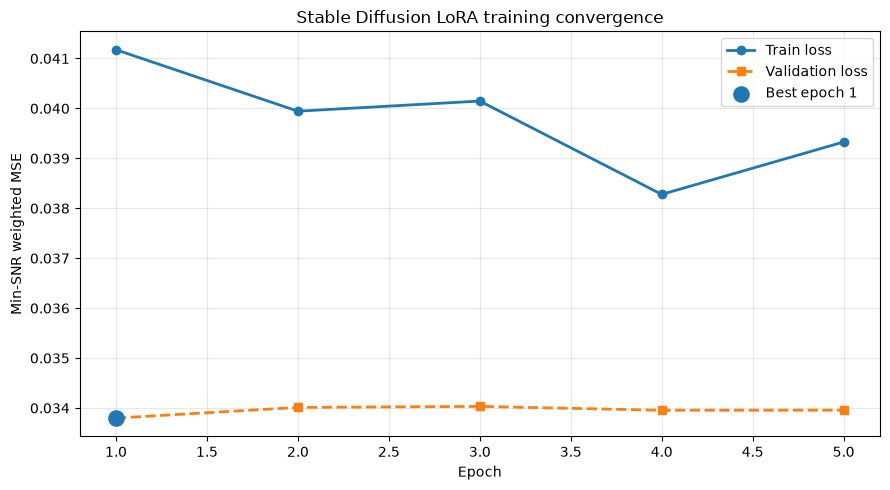

Saved: e:\GIT\Jewelery Models Development\artifacts\model1_checkpoints_fixed\loss_curve.png
Validation loss: first=0.03380, best=0.03380, relative change=0.00%


In [13]:
epochs_run = np.arange(1, len(train_losses) + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs_run, train_losses, 'o-', linewidth=2, label='Train loss')
plt.plot(epochs_run, val_losses, 's--', linewidth=2, label='Validation loss')
if best_epoch > 0:
    plt.scatter([best_epoch], [val_losses[best_epoch - 1]], s=120, zorder=5, label=f'Best epoch {best_epoch}')
plt.xlabel('Epoch')
plt.ylabel('Min-SNR weighted MSE')
plt.title('Stable Diffusion LoRA training convergence')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
curve_path = os.path.join(checkpoint_dir, 'loss_curve.png')
plt.savefig(curve_path, dpi=200)
plt.show()
print('Saved:', curve_path)

if len(val_losses) >= 2:
    first = val_losses[0]
    best = min(val_losses)
    print(f'Validation loss: first={first:.5f}, best={best:.5f}, relative change={(best-first)/first*100:.2f}%')


## 13. Load the best LoRA adapter for inference

The best validation checkpoint is used for generation. The LoRA adapter is merged into a fresh UNet for inference.


In [14]:
if not os.path.isdir(best_checkpoint_path):
    raise FileNotFoundError('Best LoRA checkpoint does not exist. Complete training first.')

print('Loading base Stable Diffusion pipeline...')
pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    safety_checker=None,
)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe = pipe.to(device)

print('Loading best LoRA adapter...')
fresh_unet = UNet2DConditionModel.from_pretrained(
    MODEL_NAME, subfolder='unet',
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
)
fresh_unet = PeftModel.from_pretrained(fresh_unet, best_checkpoint_path)
fresh_unet = fresh_unet.merge_and_unload()
pipe.unet = fresh_unet.to(device)

print('Best LoRA adapter loaded and merged.')


e:\GIT\Jewelery Models Development\.venv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Couldn't connect to the Hub: [Errno 11001] getaddrinfo failed.
Will try to load from local cache.


Loading base Stable Diffusion pipeline...


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .
'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/runwayml/stable-diffusion-v1-5/resolve/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/unet/diffusion_pytorch_model.safetensors.index.json
Retrying in 1s [Retry 1/5].


Loading best LoRA adapter...


'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/runwayml/stable-diffusion-v1-5/resolve/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/unet/diffusion_pytorch_model.safetensors.index.json
Retrying in 2s [Retry 2/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/runwayml/stable-diffusion-v1-5/resolve/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/unet/diffusion_pytorch_model.safetensors.index.json
Retrying in 4s [Retry 3/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/runwayml/stable-diffusion-v1-5/resolve/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/unet/diffusion_pytorch_model.safetensors.index.json
Retrying in 8s [Retry 4/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/runwayml/stable-diffusion-v1-5/resolve/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/unet/diffusion_pytorch_model.safetensors.index.json
Retrying in 8s [Retry 5/5].
'[Errno 1100

Best LoRA adapter loaded and merged.


## 14. Generate fixed benchmark prompts

These prompts are intentionally the same across experiments so Model 1 can be compared against later models.


Generating design 1/3...


  0%|          | 0/30 [00:00<?, ?it/s]

Generating design 2/3...


  0%|          | 0/30 [00:00<?, ?it/s]

Generating design 3/3...


  0%|          | 0/30 [00:00<?, ?it/s]

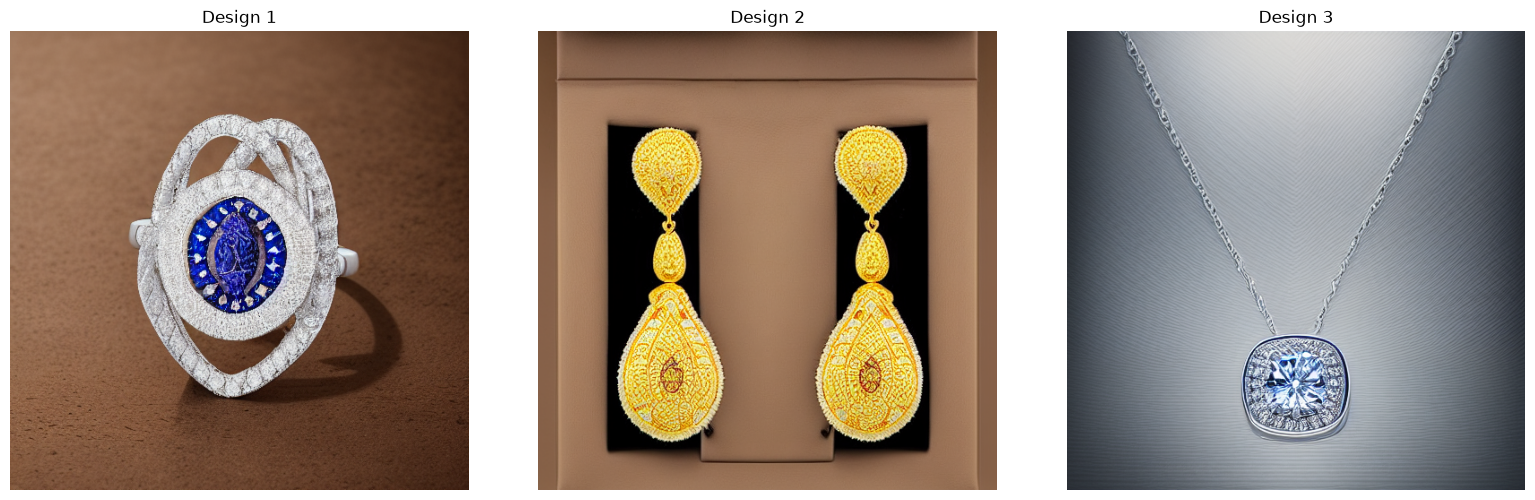

In [15]:
test_prompts = [
    'A bespoke 18K white gold ring with a 2.5 carat royal blue sapphire centerpiece, pave diamond halo, studio jewelry lighting, luxury product photography',
    'An elegant pair of 22KT yellow gold drop earrings set with vivid yellow Ceylon sapphires, fine prongs, handcrafted luxury jewelry photography',
    'A platinum pendant necklace featuring an unheated cushion cut cornflower blue sapphire solitaire, high polish mirror finish, studio product photography',
]
negative_prompt = 'low quality, blurry, distorted gemstones, asymmetrical prongs, cloudy sapphire, bad reflections, dark background, extra fingers, malformed jewelry'

generated_images = []
generator = torch.Generator(device=device).manual_seed(SEED)

for idx, prompt in enumerate(test_prompts, start=1):
    print(f'Generating design {idx}/{len(test_prompts)}...')
    with torch.inference_mode():
        image = pipe(
            prompt=prompt,
            negative_prompt=negative_prompt,
            num_inference_steps=30,
            guidance_scale=7.5,
            generator=generator,
        ).images[0]
    generated_images.append(image)

fig, axes = plt.subplots(1, len(generated_images), figsize=(16, 5))
for i, (ax, img) in enumerate(zip(axes, generated_images), start=1):
    ax.imshow(img)
    ax.set_title(f'Design {i}')
    ax.axis('off')
plt.tight_layout()
plt.show()

for i, image in enumerate(generated_images, start=1):
    image.save(os.path.join(checkpoint_dir, f'generated_design_{i}.png'))


## 15. Quantitative CLIP image-text alignment benchmark

This benchmark now evaluates **both** the base SD 1.5 model and the fine-tuned LoRA model using the same prompts and random seeds.

The score below is **cosine similarity × 100**, not the official package named `CLIPScore`. It is useful for a controlled relative comparison within this experiment.


In [16]:
print('Loading CLIP ViT-B/32 evaluation model...')
clip_model = CLIPModel.from_pretrained('openai/clip-vit-base-patch32').to(device)
clip_processor = CLIPProcessor.from_pretrained('openai/clip-vit-base-patch32')
clip_model.eval()

def compute_clip_alignment(image, prompt_text):
    inputs = clip_processor(
        text=[prompt_text],
        images=image,
        return_tensors='pt',
        padding=True,
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = clip_model(**inputs)
        image_embeds = F.normalize(outputs.image_embeds, dim=-1)
        text_embeds = F.normalize(outputs.text_embeds, dim=-1)
        similarity = (image_embeds * text_embeds).sum().item()
    return similarity * 100.0

# Fine-tuned scores
finetuned_scores = [
    compute_clip_alignment(img, prompt)
    for img, prompt in zip(generated_images, test_prompts)
]

print('Fine-tuned LoRA CLIP alignment:')
for i, score in enumerate(finetuned_scores, start=1):
    print(f'  Design {i}: {score:.2f}/100')
print(f'  Mean: {np.mean(finetuned_scores):.2f}/100')

# Optional but recommended: generate the same prompts with the BASE model.
print('\nLoading base pipeline for before/after comparison...')
base_pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    safety_checker=None,
).to(device)
base_pipe.scheduler = DPMSolverMultistepScheduler.from_config(base_pipe.scheduler.config)

base_images = []
base_scores = []

for idx, prompt in enumerate(test_prompts):
    gen = torch.Generator(device=device).manual_seed(SEED + idx)
    with torch.inference_mode():
        img = base_pipe(
            prompt=prompt,
            negative_prompt=negative_prompt,
            num_inference_steps=30,
            guidance_scale=7.5,
            generator=gen,
        ).images[0]
    base_images.append(img)
    base_scores.append(compute_clip_alignment(img, prompt))

print('Base SD 1.5 CLIP alignment:')
for i, score in enumerate(base_scores, start=1):
    print(f'  Design {i}: {score:.2f}/100')
print(f'  Mean: {np.mean(base_scores):.2f}/100')

comparison = pd.DataFrame({
    'design': [1, 2, 3],
    'base_clip_alignment': base_scores,
    'lora_clip_alignment': finetuned_scores,
})
comparison['change'] = comparison['lora_clip_alignment'] - comparison['base_clip_alignment']
display(comparison)

comparison.to_csv(os.path.join(checkpoint_dir, 'clip_alignment_comparison.csv'), index=False)


Could not reach the Hub ([Errno 11001] getaddrinfo failed). Using cached commit hash for 'openai/clip-vit-base-patch32'.


Loading CLIP ViT-B/32 evaluation model...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Could not reach the Hub ([Errno 11001] getaddrinfo failed). Using cached commit hash for 'openai/clip-vit-base-patch32'.
Couldn't connect to the Hub: [Errno 11001] getaddrinfo failed.
Will try to load from local cache.


Fine-tuned LoRA CLIP alignment:
  Design 1: 35.58/100
  Design 2: 33.88/100
  Design 3: 34.61/100
  Mean: 34.69/100

Loading base pipeline for before/after comparison...


...

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

Base SD 1.5 CLIP alignment:
  Design 1: 35.53/100
  Design 2: 34.81/100
  Design 3: 36.55/100
  Mean: 35.63/100


,design,base_clip_alignment,lora_clip_alignment,change
0,1,35.525322,35.576963,0.051641
1,2,34.810442,33.881968,-0.928473
2,3,36.550799,34.614244,-1.936555


## 16. Final experiment report

Use this cell after training to print the important configuration and outcome values for your project report.

### How to interpret the run
- **Good:** validation loss improves for several epochs and generated jewelry becomes more domain-specific.
- **Probably overfitting:** training loss keeps improving while validation loss clearly worsens and generated diversity collapses.
- **Probably under-training:** both losses are noisy/flat and generations remain close to generic SD 1.5.
- **Not automatically a problem:** train loss does not have to decrease monotonically.
- **Most important:** compare generated samples using fixed prompts, not loss alone.


In [17]:
report = {
    'model': MODEL_NAME,
    'dataset_records': len(df),
    'train_samples': len(train_df),
    'validation_samples': len(val_df),
    'epochs_completed': len(train_losses),
    'best_epoch': best_epoch,
    'best_validation_loss': best_val_loss,
    'trainable_lora_parameters': trainable_count,
    'total_unet_parameters': total_count,
    'trainable_percentage': 100 * trainable_count / total_count,
    'learning_rate': LEARNING_RATE,
    'min_snr_gamma': MIN_SNR_GAMMA,
    'lora_r': LORA_R,
    'lora_alpha': LORA_ALPHA,
    'batch_size': BATCH_SIZE,
    'effective_batch_size': BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS,
    'early_stopping_patience': EARLY_STOP_PATIENCE,
}
print(json.dumps(report, indent=2))
print('\nArtifacts saved under:', checkpoint_dir)


{
  "model": "runwayml/stable-diffusion-v1-5",
  "dataset_records": 1503,
  "train_samples": 1303,
  "validation_samples": 200,
  "epochs_completed": 5,
  "best_epoch": 1,
  "best_validation_loss": 0.03379836590029299,
  "trainable_lora_parameters": 3188736,
  "total_unet_parameters": 862709700,
  "trainable_percentage": 0.3696186561945461,
  "learning_rate": 2e-05,
  "min_snr_gamma": 5.0,
  "lora_r": 16,
  "lora_alpha": 16,
  "batch_size": 4,
  "effective_batch_size": 8,
  "early_stopping_patience": 4
}

Artifacts saved under: e:\GIT\Jewelery Models Development\artifacts\model1_checkpoints_fixed
